<a href="https://colab.research.google.com/github/vardiansyahnabil/Latihan-pratikum/blob/main/Praktikum_Analisis_dan_Visualisasi_Data_Nusantara_Mart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# Memanggil library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan grafik
sns.set_style('whitegrid')

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [13]:
# Membaca file CSV
df = pd.read_csv('/content/penjualan_nusantaramart - penjualan_nusantaramart.csv')

# Menampilkan 5 data pertama
df.head()

,order_id,tanggal,kategori_produk,nama_produk,wilayah,jumlah,harga_satuan,total,metode_pembayaran,rating_pelanggan
0,1146,2026-01-03,Olahraga,Matras Yoga,Malang,5,90000,450000,E-Wallet,4
1,1166,2026-01-05,Fashion,Celana Jeans,Surabaya,5,175000,875000,Transfer Bank,5
2,1190,2026-01-05,Kesehatan,Masker Medis Box,Semarang,4,30000,120000,Kartu Kredit,3
3,1219,2026-01-08,Makanan & Minuman,Kopi Kemasan 200g,Bandung,4,28000,112000,E-Wallet,3
4,1133,2026-01-10,Fashion,Tas Ransel,Surabaya,4,130000,520000,Kartu Kredit,4


In [14]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris dan kolom: (220, 10)
Jumlah baris: 220
Jumlah kolom: 10


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   order_id           220 non-null    int64 
 1   tanggal            220 non-null    object
 2   kategori_produk    220 non-null    object
 3   nama_produk        220 non-null    object
 4   wilayah            220 non-null    object
 5   jumlah             220 non-null    int64 
 6   harga_satuan       220 non-null    int64 
 7   total              220 non-null    int64 
 8   metode_pembayaran  220 non-null    object
 9   rating_pelanggan   220 non-null    int64 
dtypes: int64(5), object(5)
memory usage: 17.3+ KB


In [16]:
df.describe()

,order_id,jumlah,harga_satuan,total,rating_pelanggan
count,220.000000,220.000000,220.000000,2.200000e+02,220.000000
mean,1110.500000,3.622727,63459.090909,2.384864e+05,4.154545
std,63.652704,4.865162,45395.201797,3.714249e+05,0.784395
min,1001.000000,1.000000,15000.000000,1.500000e+04,2.000000
25%,1055.750000,1.000000,28000.000000,5.500000e+04,4.000000
50%,1110.500000,3.000000,48000.000000,1.250000e+05,4.000000
75%,1165.250000,4.000000,90000.000000,2.600000e+05,5.000000
max,1220.000000,40.000000,175000.000000,3.400000e+06,5.000000


In [17]:
print("Jumlah data kosong setiap kolom:")
print(df.isnull().sum())

Jumlah data kosong setiap kolom:
order_id             0
tanggal              0
kategori_produk      0
nama_produk          0
wilayah              0
jumlah               0
harga_satuan         0
total                0
metode_pembayaran    0
rating_pelanggan     0
dtype: int64


In [18]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


In [19]:
# Mengubah tanggal menjadi format datetime
df['tanggal'] = pd.to_datetime(df['tanggal'])

# Memeriksa tipe data
print(df.dtypes)

order_id                      int64
tanggal              datetime64[ns]
kategori_produk              object
nama_produk                  object
wilayah                      object
jumlah                        int64
harga_satuan                  int64
total                         int64
metode_pembayaran            object
rating_pelanggan              int64
dtype: object


In [20]:
# Menghapus duplikat jika ada
df = df.drop_duplicates()

# Memeriksa data kosong
print(df.isnull().sum())

# Menampilkan 5 data pertama
df.head()

order_id             0
tanggal              0
kategori_produk      0
nama_produk          0
wilayah              0
jumlah               0
harga_satuan         0
total                0
metode_pembayaran    0
rating_pelanggan     0
dtype: int64


,order_id,tanggal,kategori_produk,nama_produk,wilayah,jumlah,harga_satuan,total,metode_pembayaran,rating_pelanggan
0,1146,2026-01-03,Olahraga,Matras Yoga,Malang,5,90000,450000,E-Wallet,4
1,1166,2026-01-05,Fashion,Celana Jeans,Surabaya,5,175000,875000,Transfer Bank,5
2,1190,2026-01-05,Kesehatan,Masker Medis Box,Semarang,4,30000,120000,Kartu Kredit,3
3,1219,2026-01-08,Makanan & Minuman,Kopi Kemasan 200g,Bandung,4,28000,112000,E-Wallet,3
4,1133,2026-01-10,Fashion,Tas Ransel,Surabaya,4,130000,520000,Kartu Kredit,4


In [21]:
# Menghitung statistik penjualan

mean_total = df['total'].mean()
median_total = df['total'].median()
modus_total = df['total'].mode()[0]
range_total = df['total'].max() - df['total'].min()
variansi_total = df['total'].var()
std_total = df['total'].std()

q1 = df['total'].quantile(0.25)
q2 = df['total'].quantile(0.50)
q3 = df['total'].quantile(0.75)

iqr = q3 - q1

print("MEAN:", mean_total)
print("MEDIAN:", median_total)
print("MODUS:", modus_total)
print("RANGE:", range_total)
print("VARIANSI:", variansi_total)
print("STANDAR DEVIASI:", std_total)
print("Q1:", q1)
print("Q2:", q2)
print("Q3:", q3)
print("IQR:", iqr)

MEAN: 238486.36363636365
MEDIAN: 125000.0
MODUS: 180000
RANGE: 3385000
VARIANSI: 137956442735.5749
STANDAR DEVIASI: 371424.88168615586
Q1: 55000.0
Q2: 125000.0
Q3: 260000.0
IQR: 205000.0


In [22]:
rata_kategori = df.groupby('kategori_produk')['total'].mean()

print("Rata-rata penjualan setiap kategori:")
print(rata_kategori.sort_values(ascending=False))

Rata-rata penjualan setiap kategori:
kategori_produk
Elektronik           363541.666667
Fashion              353900.000000
Olahraga             209071.428571
Kesehatan            148972.972973
Makanan & Minuman     70441.860465
Name: total, dtype: float64


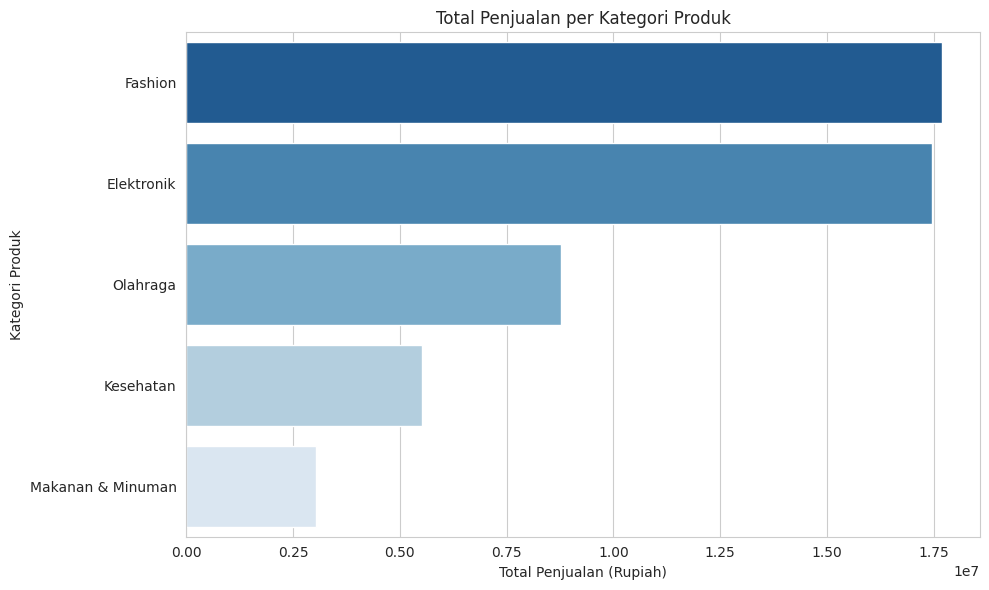

In [23]:
# Menghitung total penjualan setiap kategori
total_kategori = df.groupby('kategori_produk')['total'].sum()
total_kategori = total_kategori.sort_values(ascending=False)

# Membuat grafik
plt.figure(figsize=(10, 6))

sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    hue=total_kategori.index,
    palette='Blues_r',
    legend=False
)

plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rupiah)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

Berdasarkan hasil perhitungan dataset:
- Fashion memiliki total penjualan tertinggi sebesar Rp17.695.000.
- Elektronik berada di posisi kedua sebesar Rp17.450.000.
- Makanan & Minuman memiliki penjualan terendah sebesar Rp3.029.000.

Jawaban Tugas Analisis 2:

Kategori dengan penjualan tertinggi adalah Fashion, sedangkan kategori dengan penjualan terendah adalah Makanan & Minuman.

Rekomendasi bisnis: perusahaan dapat mempertahankan stok produk Fashion dan Elektronik karena memberikan kontribusi penjualan terbesar. Untuk kategori Makanan & Minuman, perusahaan dapat melakukan promosi dan mengevaluasi strategi pemasaran agar penjualannya meningkat.

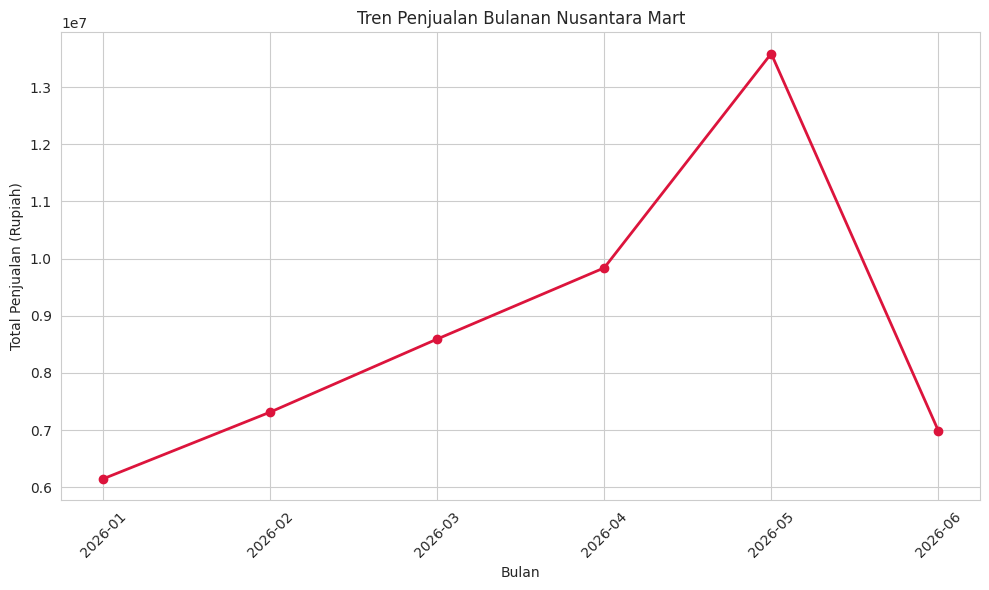

In [24]:
# Mengelompokkan penjualan berdasarkan bulan
df['bulan'] = df['tanggal'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['total'].sum()

# Membuat grafik garis
plt.figure(figsize=(10, 6))

plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson',
    linewidth=2
)

plt.title('Tren Penjualan Bulanan Nusantara Mart')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rupiah)')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

Jawaban Tugas Analisis 3:

Bulan dengan penjualan tertinggi adalah Mei 2026, yaitu Rp13.585.000.

Tren penjualan dari Januari hingga Mei cenderung meningkat. Namun, pada Juni terjadi penurunan cukup besar. Kemungkinan penyebabnya adalah perubahan permintaan pelanggan, berkurangnya promosi, atau perubahan kondisi pasar. Penyebab pastinya belum dapat dipastikan hanya dari dataset ini.

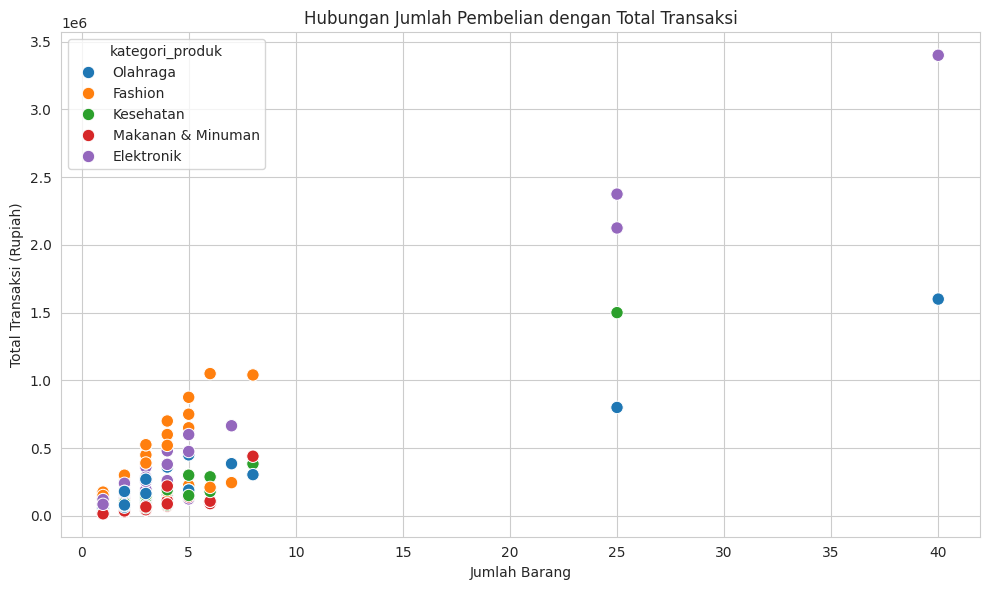

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='jumlah',
    y='total',
    hue='kategori_produk',
    s=80
)

plt.title('Hubungan Jumlah Pembelian dengan Total Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total Transaksi (Rupiah)')

plt.tight_layout()
plt.show()

Jawaban Tugas Analisis 4:

Terlihat hubungan positif antara jumlah barang yang dibeli dengan total transaksi. Artinya, semakin banyak barang yang dibeli, nilai transaksi cenderung semakin tinggi.

Hasil perhitungan korelasi Pearson pada dataset adalah sekitar 0,854, yang menunjukkan hubungan positif yang kuat. Terdapat beberapa titik yang jauh dari pola umum, terutama transaksi dengan jumlah barang 25 hingga 40 unit. Titik tersebut perlu diperiksa lebih lanjut karena mungkin merupakan pembelian dalam jumlah besar.

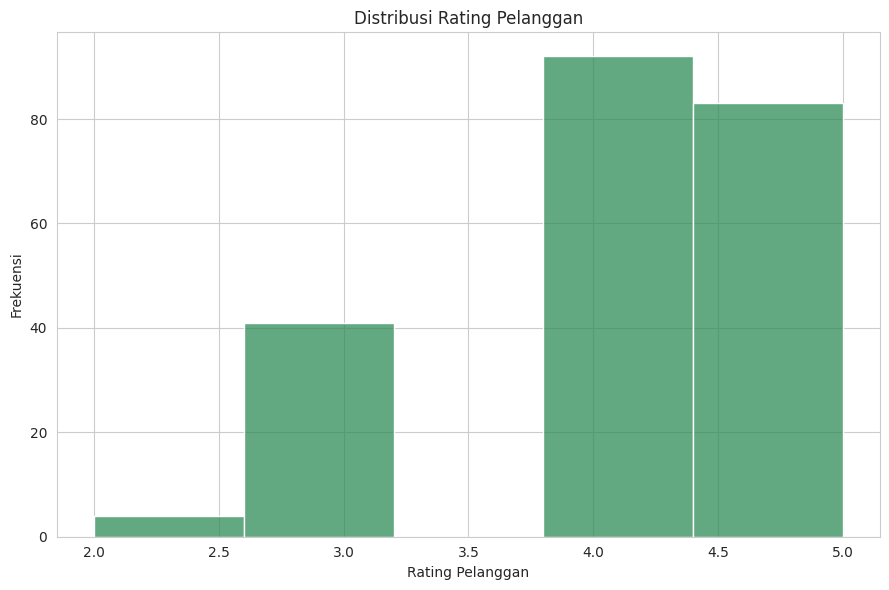

In [26]:
plt.figure(figsize=(9, 6))

sns.histplot(
    df['rating_pelanggan'],
    bins=5,
    color='seagreen'
)

plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating Pelanggan')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Jawaban Tugas Analisis 5 bagian pertama:

Distribusi rating pelanggan cenderung tinggi. Rating 4 merupakan rating yang paling banyak diberikan, yaitu 92 pelanggan, diikuti rating 5 sebanyak 83 pelanggan.

Rata-rata rating pelanggan adalah 4,15 dari 5, sehingga secara umum pelanggan memberikan penilaian yang cukup baik terhadap produk Nusantara Mart.

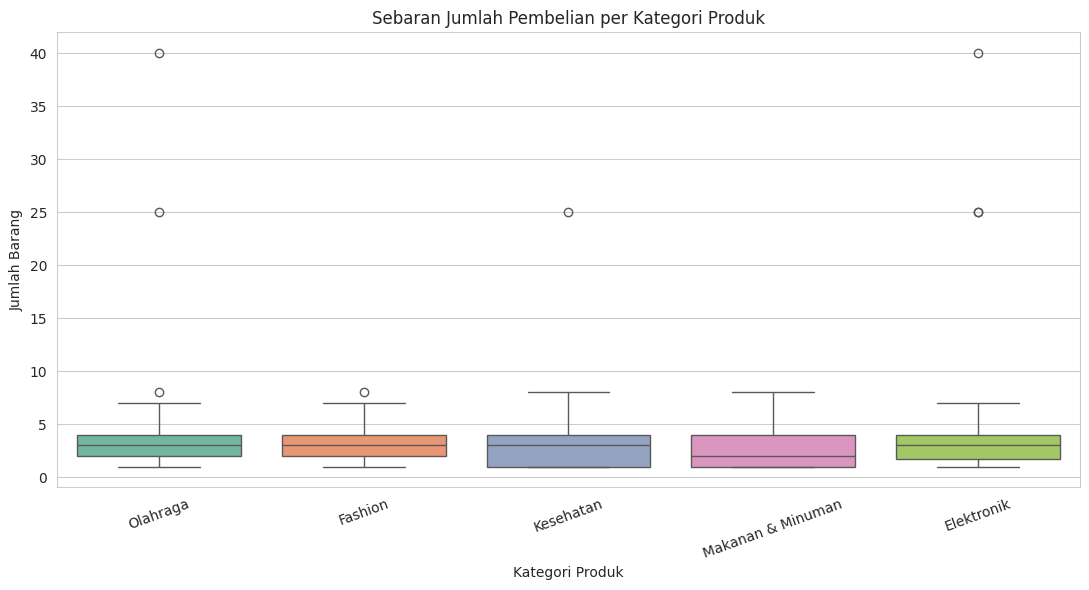

In [27]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='kategori_produk',
    y='jumlah',
    hue='kategori_produk',
    palette='Set2',
    legend=False
)

plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Jumlah Barang')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [28]:
# Menghitung Q1 dan Q3
Q1 = df['jumlah'].quantile(0.25)
Q3 = df['jumlah'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Batas bawah dan batas atas
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

# Menampilkan data outlier
outlier = df[
    (df['jumlah'] < batas_bawah) |
    (df['jumlah'] > batas_atas)
]

print("\nData yang termasuk outlier:")
display(outlier[
    ['order_id', 'kategori_produk', 'nama_produk', 'jumlah', 'total']
])

Q1: 1.0
Q3: 4.0
IQR: 3.0
Batas bawah: -3.5
Batas atas: 8.5

Data yang termasuk outlier:


,order_id,kategori_produk,nama_produk,jumlah,total
39,1156,Elektronik,Earphone Bluetooth,40,3400000
76,1066,Olahraga,Skipping Rope,25,800000
79,1214,Kesehatan,Termometer Digital,25,1500000
121,1158,Elektronik,Speaker Mini,25,2375000
148,1021,Elektronik,Earphone Bluetooth,25,2125000
151,1141,Olahraga,Botol Minum 1L,40,1600000


Jawaban Tugas Analisis 5 bagian kedua:

Terdapat beberapa titik di luar pola umum boxplot. Hal tersebut menunjukkan adanya transaksi dengan jumlah barang yang jauh lebih banyak dibandingkan transaksi lainnya. Kemungkinan penyebabnya adalah pembelian dalam jumlah besar oleh reseller atau pelanggan yang membeli barang untuk kebutuhan tertentu. Namun, hal tersebut perlu diperiksa lebih lanjut sebelum dinyatakan sebagai penyebab sebenarnya.

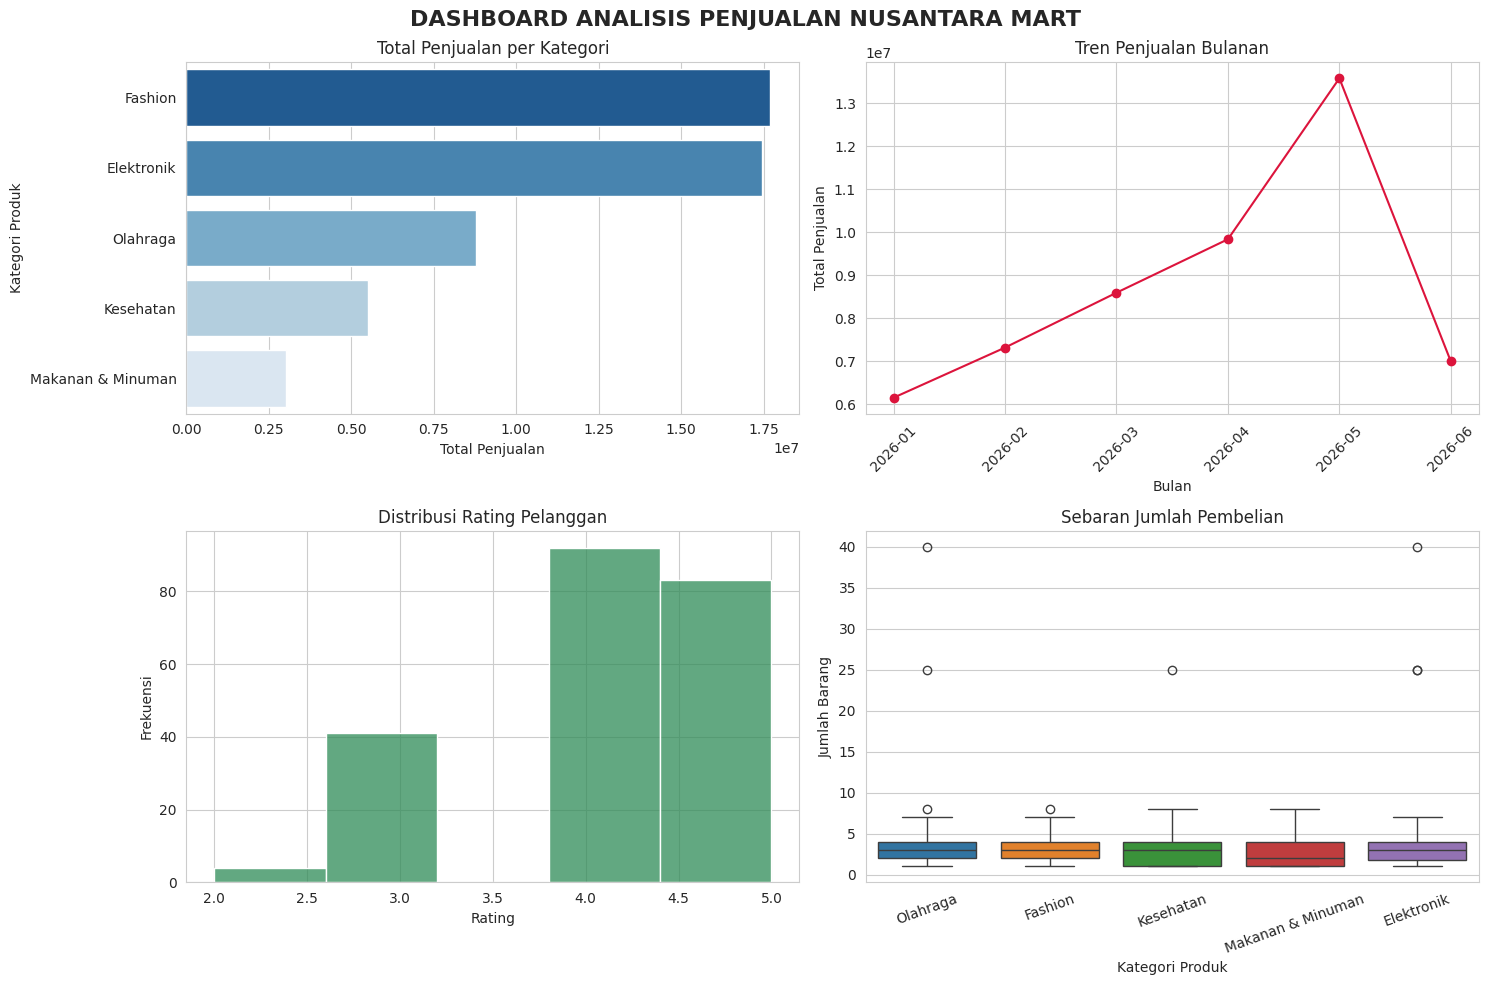

In [29]:
# Membuat dashboard dengan 4 grafik
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Grafik 1: Bar Chart
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    hue=total_kategori.index,
    palette='Blues_r',
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Total Penjualan per Kategori')
axes[0, 0].set_xlabel('Total Penjualan')
axes[0, 0].set_ylabel('Kategori Produk')

# Grafik 2: Line Chart
axes[0, 1].plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson'
)

axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Total Penjualan')
axes[0, 1].tick_params(axis='x', rotation=45)

# Grafik 3: Histogram
sns.histplot(
    df['rating_pelanggan'],
    bins=5,
    ax=axes[1, 0],
    color='seagreen'
)

axes[1, 0].set_title('Distribusi Rating Pelanggan')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frekuensi')

# Grafik 4: Boxplot
sns.boxplot(
    data=df,
    x='kategori_produk',
    y='jumlah',
    hue='kategori_produk',
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Sebaran Jumlah Pembelian')
axes[1, 1].set_xlabel('Kategori Produk')
axes[1, 1].set_ylabel('Jumlah Barang')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.suptitle(
    'DASHBOARD ANALISIS PENJUALAN NUSANTARA MART',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

Jawaban Tugas Analisis 6:

Keuntungan menyajikan beberapa grafik dalam satu dashboard adalah memudahkan manajer melihat berbagai informasi penjualan secara bersamaan. Dashboard juga membantu membandingkan kategori produk, mengetahui tren penjualan, memahami rating pelanggan, serta mendeteksi transaksi yang tidak biasa.

Jika menjadi manajer Nusantara Mart, saya akan mempertahankan penjualan Fashion dan Elektronik, meningkatkan promosi Makanan & Minuman, mengevaluasi penurunan penjualan pada bulan Juni, dan memantau transaksi dalam jumlah besar.

In [30]:
# Total seluruh penjualan
total_penjualan = df['total'].sum()

# Rata-rata transaksi
rata_transaksi = df['total'].mean()

# Kategori dengan total penjualan tertinggi
kategori_terlaris = df.groupby(
    'kategori_produk'
)['total'].sum().idxmax()

# Wilayah dengan penjualan tertinggi
wilayah_teratas = df.groupby(
    'wilayah'
)['total'].sum().idxmax()

# Rata-rata rating
rating_rata = df['rating_pelanggan'].mean()

print("===== RINGKASAN PENJUALAN NUSANTARA MART =====")
print(f"Total Penjualan       : Rp{total_penjualan:,.0f}")
print(f"Rata-rata Transaksi   : Rp{rata_transaksi:,.2f}")
print(f"Kategori Terlaris     : {kategori_terlaris}")
print(f"Wilayah Penjualan     : {wilayah_teratas}")
print(f"Rating Rata-rata      : {rating_rata:.2f}/5")

===== RINGKASAN PENJUALAN NUSANTARA MART =====
Total Penjualan       : Rp52,467,000
Rata-rata Transaksi   : Rp238,486.36
Kategori Terlaris     : Fashion
Wilayah Penjualan     : Surabaya
Rating Rata-rata      : 4.15/5
